# FDS Assignment 1 – Case Study 6
## Comparative Analysis of Classification Algorithms for Bank Marketing Prediction

**Student:** V. Sai Eshwar  
**Roll Number:** 160124733205  
**Section:** CSE-3 | **Year:** Third Year  
**Subject:** Fundamentals of Data Science  
**Faculty:** Smt. S. Durga Devi

### Problem statement
Predict whether a customer subscribes to a term deposit (`y`) using customer, campaign and previous-contact attributes. Compare Logistic Regression, Decision Tree, K-Nearest Neighbours (KNN), and Random Forest.

**Important design decision:** `duration` is excluded because it is only known after the current call and would not be available for a realistic pre-contact prediction. The target is `y`, where `yes` is the positive class.

## 1. Imports and reproducibility
The fixed random seed makes the train-test split reproducible. The same stratified 80:20 split is used for all four models.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, roc_auc_score, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load and understand the dataset
The source CSV uses a semicolon delimiter. The full dataset contains 45,211 rows and 17 columns, including the target `y`.

In [2]:
df = pd.read_csv("bank-full.csv", sep=";")

print("First 10 records:")
display(df.head(10))
print("Dataset dimensions:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nDescriptive statistics:")
display(df.describe(include="all").T)

First 10 records:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


Dataset dimensions: (45211, 17)

Data types:


,dtype
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


## 3. Data quality and target distribution
In this dataset, the string `unknown` appears in some categorical fields. It is retained as an explicit category rather than silently treated as a blank. Duplicate rows are counted and reported; they are not automatically deleted.

Missing values by column:


,missing_count
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


Rows containing at least one exact duplicate: 0

Target counts:


,count,percentage
y,,
no,39922,88.3
yes,5289,11.7


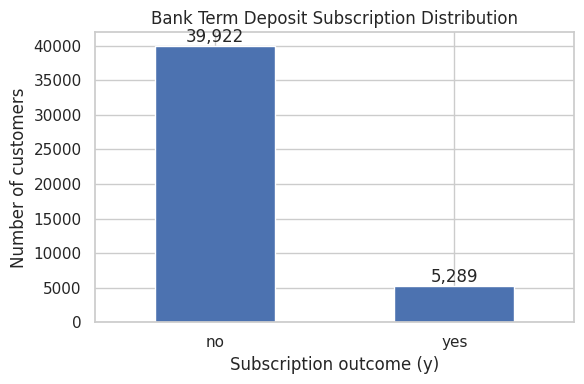

In [3]:
print("Missing values by column:")
display(df.isna().sum().to_frame("missing_count"))
print("Rows containing at least one exact duplicate:", int(df.duplicated().sum()))
print("\nTarget counts:")
target_counts = df["y"].value_counts().reindex(["no", "yes"])
target_percent = df["y"].value_counts(normalize=True).reindex(["no", "yes"]) * 100
target_summary = pd.DataFrame({"count": target_counts, "percentage": target_percent.round(2)})
display(target_summary)

ax = target_counts.plot(kind="bar", figsize=(6,4), title="Bank Term Deposit Subscription Distribution")
ax.set_xlabel("Subscription outcome (y)")
ax.set_ylabel("Number of customers")
ax.tick_params(axis="x", rotation=0)
for bar in ax.patches:
    ax.annotate(f"{int(bar.get_height()):,}", (bar.get_x()+bar.get_width()/2, bar.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 4. Exploratory data analysis
The graphs below show target subscription rates for selected categorical and numerical attributes. A rate is descriptive, not proof that the attribute causes subscription.

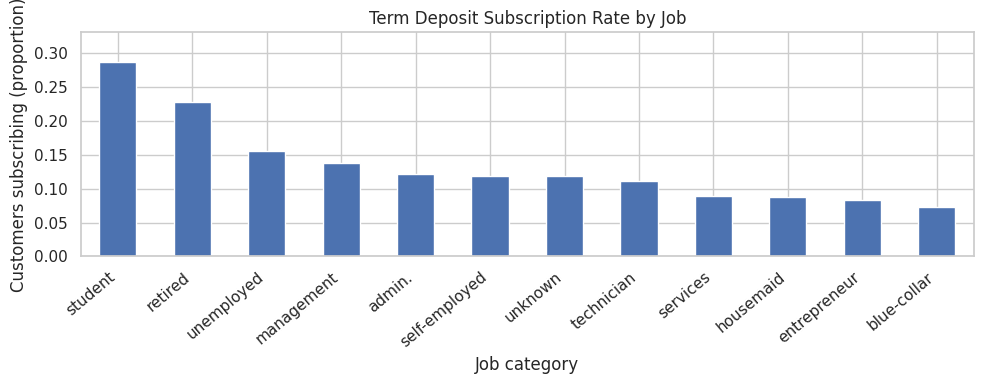

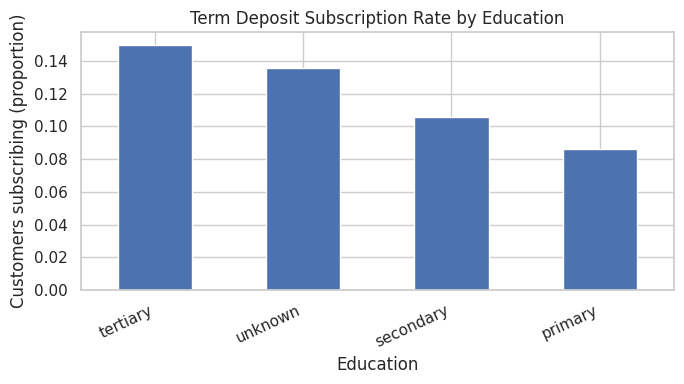

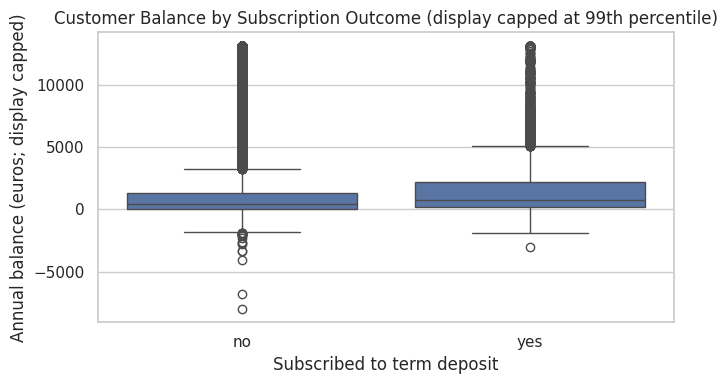

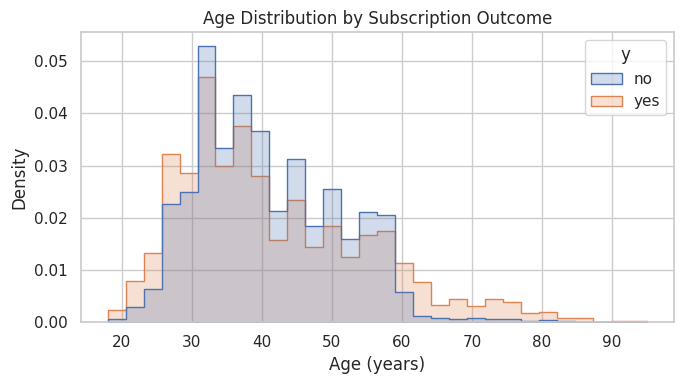

Three observations to verify from the plots:
1. The target classes are imbalanced; non-subscribers substantially outnumber subscribers.
2. Subscription rates vary across job categories; some groups show higher observed rates than others.
3. Balance and age distributions overlap between outcomes, so neither feature alone cleanly separates subscribers from non-subscribers.


In [4]:
# Subscription rate by job
job_rate = pd.crosstab(df["job"], df["y"], normalize="index")["yes"].sort_values(ascending=False)
ax = job_rate.plot(kind="bar", figsize=(10,4), title="Term Deposit Subscription Rate by Job")
ax.set_xlabel("Job category")
ax.set_ylabel("Customers subscribing (proportion)")
ax.set_ylim(0, max(job_rate.max()*1.15, 0.05))
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

# Subscription rate by education
edu_rate = pd.crosstab(df["education"], df["y"], normalize="index")["yes"].sort_values(ascending=False)
ax = edu_rate.plot(kind="bar", figsize=(7,4), title="Term Deposit Subscription Rate by Education")
ax.set_xlabel("Education")
ax.set_ylabel("Customers subscribing (proportion)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# Balance distribution by target, clipping display range at 99th percentile to make the main distribution visible
plot_df = df[["balance", "y"]].copy()
upper = plot_df["balance"].quantile(0.99)
plot_df["balance_display"] = plot_df["balance"].clip(upper=upper)
plt.figure(figsize=(7,4))
sns.boxplot(data=plot_df, x="y", y="balance_display")
plt.title("Customer Balance by Subscription Outcome (display capped at 99th percentile)")
plt.xlabel("Subscribed to term deposit")
plt.ylabel("Annual balance (euros; display capped)")
plt.tight_layout()
plt.show()

# Age distribution by target
plt.figure(figsize=(7,4))
sns.histplot(data=df, x="age", hue="y", bins=30, stat="density", common_norm=False, element="step")
plt.title("Age Distribution by Subscription Outcome")
plt.xlabel("Age (years)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

print("Three observations to verify from the plots:")
print("1. The target classes are imbalanced; non-subscribers substantially outnumber subscribers.")
print("2. Subscription rates vary across job categories; some groups show higher observed rates than others.")
print("3. Balance and age distributions overlap between outcomes, so neither feature alone cleanly separates subscribers from non-subscribers.")

## 5. Prepare features and split the data
The `duration` column is excluded as required. Numeric features are median-imputed and scaled; categorical features are imputed with the most frequent value and one-hot encoded. `unknown` remains a valid category. Stratification preserves approximately the same target proportions in training and test sets.

In [5]:
target = "y"
X = df.drop(columns=[target, "duration"])
y = (df[target] == "yes").astype(int)  # yes=1 is the positive class

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Predictor columns:", X.shape[1], "(duration excluded)")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Training rows:", X_train.shape[0], "| Test rows:", X_test.shape[0])
print("\nTarget rate in training:", round(y_train.mean()*100, 2), "% yes")
print("Target rate in test:", round(y_test.mean()*100, 2), "% yes")

Predictor columns: 15 (duration excluded)
Numeric features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Training rows: 36168 | Test rows: 9043

Target rate in training: 11.7 % yes
Target rate in test: 11.7 % yes


## 6. Train four classification models
All models use the same split and preprocessing. KNN benefits from scaled numerical features. Decision Tree and Random Forest are tree-based classifiers; the shared preprocessing keeps categorical data usable for all models.

In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight=None, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced", min_samples_leaf=5),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights="distance"),
    "Random Forest": RandomForestClassifier(n_estimators=120, random_state=RANDOM_STATE,
                                            n_jobs=-1, class_weight="balanced_subsample",
                                            min_samples_leaf=2)
}

fitted_models = {}
results = []
predictions = {}
probabilities = {}

for name, estimator in models.items():
    print("Training:", name)
    pipe = Pipeline(steps=[("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    fitted_models[name] = pipe
    predictions[name] = y_pred
    probabilities[name] = y_prob
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
display(results_df.round(4))

Training: Logistic Regression


Training: Decision Tree


Training: KNN


Training: Random Forest


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.8851,0.5117,0.3922,0.4441,0.8002
1,Decision Tree,0.7485,0.2432,0.5444,0.3363,0.6812
2,KNN,0.8891,0.5758,0.1975,0.2942,0.7138
3,Logistic Regression,0.8933,0.6632,0.1786,0.2815,0.7717


## 7. Compare evaluation metrics
Accuracy alone is not sufficient because subscribers are the minority class. Precision measures the reliability of positive predictions; recall measures the fraction of actual subscribers identified; F1 balances precision and recall. ROC-AUC evaluates ranking across thresholds.

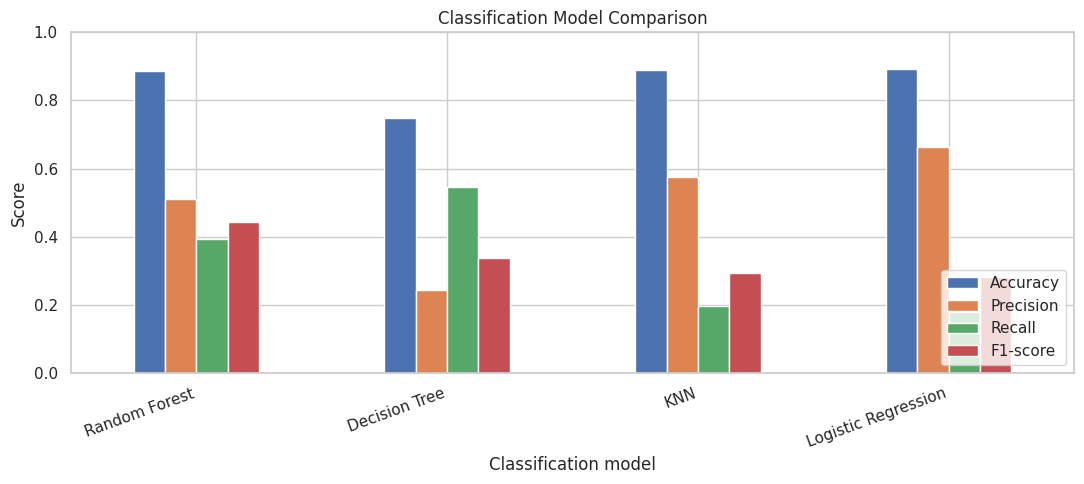

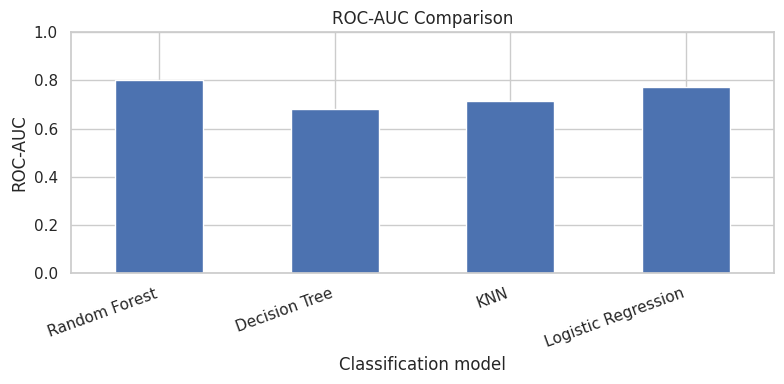

In [7]:
metric_cols = ["Accuracy", "Precision", "Recall", "F1-score"]
plot_metrics = results_df.set_index("Model")[metric_cols]
ax = plot_metrics.plot(kind="bar", figsize=(11,5), ylim=(0,1), title="Classification Model Comparison")
ax.set_xlabel("Classification model")
ax.set_ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

ax = results_df.set_index("Model")["ROC-AUC"].plot(kind="bar", figsize=(8,4), ylim=(0,1),
                                                    title="ROC-AUC Comparison")
ax.set_xlabel("Classification model")
ax.set_ylabel("ROC-AUC")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 8. Confusion matrices
The positive class is `yes` (subscribed). A false negative is a subscriber the model misses; a false positive is a customer predicted to subscribe who does not. For campaign targeting, false negatives may mean missed opportunities, while false positives can waste contact resources.

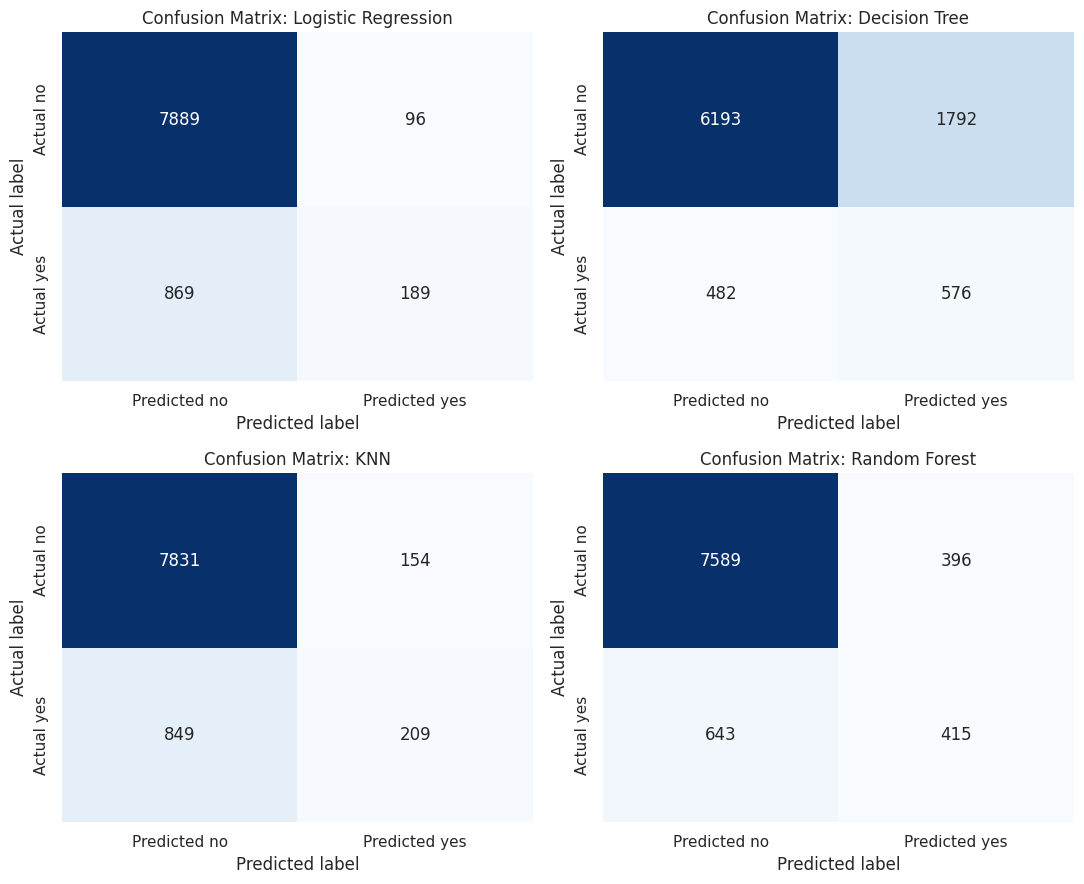


 Logistic Regression
              precision    recall  f1-score   support

          no       0.90      0.99      0.94      7985
         yes       0.66      0.18      0.28      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.58      0.61      9043
weighted avg       0.87      0.89      0.87      9043


 Decision Tree
              precision    recall  f1-score   support

          no       0.93      0.78      0.84      7985
         yes       0.24      0.54      0.34      1058

    accuracy                           0.75      9043
   macro avg       0.59      0.66      0.59      9043
weighted avg       0.85      0.75      0.79      9043


 KNN
              precision    recall  f1-score   support

          no       0.90      0.98      0.94      7985
         yes       0.58      0.20      0.29      1058

    accuracy                           0.89      9043
   macro avg       0.74      0.59      0.62      9043
weighted avg       0.86      0

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11,9))
for ax, name in zip(axes.ravel(), models.keys()):
    cm = confusion_matrix(y_test, predictions[name], labels=[0,1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Predicted no", "Predicted yes"],
                yticklabels=["Actual no", "Actual yes"])
    ax.set_title(f"Confusion Matrix: {name}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
plt.tight_layout()
plt.show()

for name in models:
    print("\n", name)
    print(classification_report(y_test, predictions[name], target_names=["no", "yes"], zero_division=0))

## 9. ROC curves
The ROC curve compares true-positive rate with false-positive rate across classification thresholds. A higher ROC-AUC indicates better ranking ability, but the final threshold should also reflect campaign capacity and the cost of errors.

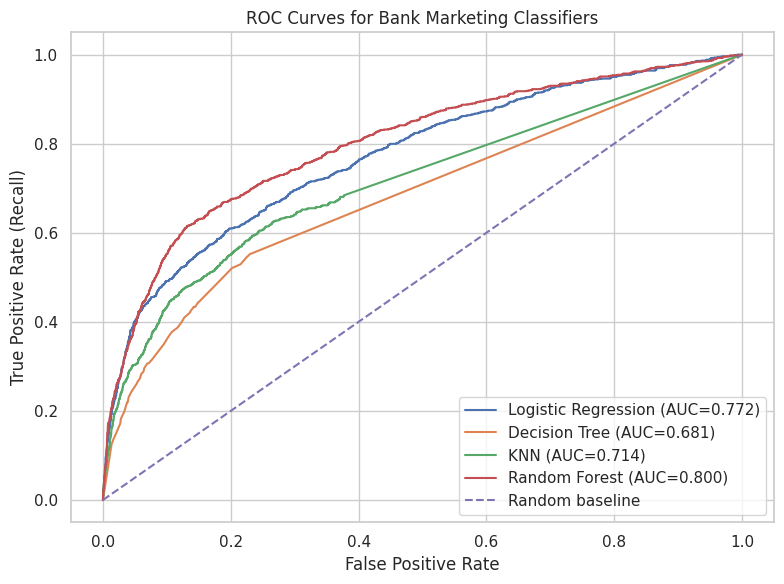

In [9]:
plt.figure(figsize=(8,6))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    auc = roc_auc_score(y_test, probabilities[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0,1], [0,1], linestyle="--", label="Random baseline")
plt.title("ROC Curves for Bank Marketing Classifiers")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 10. Best model and business interpretation
The code below identifies the top model by F1-score and reports its recall, precision, and ROC-AUC. This is a practical default when balancing the identification of subscribers with the reliability of positive predictions. The bank should revisit this choice if it has a specific cost ratio or a fixed call capacity.

In [10]:
best_row = results_df.sort_values(["F1-score", "ROC-AUC"], ascending=False).iloc[0]
best_model_name = best_row["Model"]
print("Selected model by F1-score (ROC-AUC used as tie-breaker):", best_model_name)
print(best_row.to_string())

print("\nBusiness recommendations:")
print("1. Use the model to rank customers by predicted subscription probability and prioritize outreach within the available campaign budget.")
print("2. Choose a decision threshold based on campaign capacity and the relative cost of missed subscribers versus unnecessary calls; validate it on new campaign data.")
print("\nLimitations:")
print("1. The target is imbalanced, so default-threshold models may miss many subscribers; precision and recall depend on the threshold.")
print("2. Historical patterns may not generalize to future campaigns because customer behavior and economic conditions can change.")
print("3. Excluding duration makes this a realistic pre-contact model, but may reduce predictive performance compared with models that use information only available after a call.")

Selected model by F1-score (ROC-AUC used as tie-breaker): Random Forest
Model        Random Forest
Accuracy          0.885105
Precision         0.511714
Recall             0.39225
F1-score          0.444088
ROC-AUC           0.800185

Business recommendations:
1. Use the model to rank customers by predicted subscription probability and prioritize outreach within the available campaign budget.
2. Choose a decision threshold based on campaign capacity and the relative cost of missed subscribers versus unnecessary calls; validate it on new campaign data.

Limitations:
1. The target is imbalanced, so default-threshold models may miss many subscribers; precision and recall depend on the threshold.
2. Historical patterns may not generalize to future campaigns because customer behavior and economic conditions can change.
3. Excluding duration makes this a realistic pre-contact model, but may reduce predictive performance compared with models that use information only available after a call.


## 11. Conclusion
Four classification algorithms were trained and evaluated using the same stratified train-test split. The final recommendation should be based on the generated comparison table, especially recall, F1-score and ROC-AUC, rather than accuracy alone. The selected model can support campaign prioritization, but its threshold should reflect business costs and be validated on later campaign data.

## References
Moro, S., Laureano, R., & Cortez, P. (2011). *Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology*. Proceedings of the European Simulation and Modelling Conference, 117–121.

Dataset documentation: `bank-names.txt` supplied with the Bank Marketing dataset.